In [17]:
import pandas as pd

data = {
    "precision": [0.59, 0.99, 0.67, 1.00, 0.40, 0.58, 0.87, 0.42, 0.92],
    "recall":    [0.89, 0.73, 0.15, 0.79, 0.48, 0.84, 0.63, 0.87, 0.41],
    "f1-score":  [0.71, 0.84, 0.25, 0.88, 0.44, 0.68, 0.73, 0.57, 0.57],
    "support":   [1041, 1057, 1152, 1156, 890, 1354, 877, 1045, 1432]
}

report_df = pd.DataFrame(data)
report_df.index = [str(i) for i in range(9)]

print("\n===== CLASSIFICATION REPORT =====")
print(report_df)

# Add summary rows
summary = pd.DataFrame({
    "precision": [0.64, 0.72, 0.72],
    "recall":    [0.64, 0.64, 0.64],
    "f1-score":  [0.64, 0.63, 0.63],
    "support":   [10004, 10004, 10004]
}, index=["accuracy", "macro avg", "weighted avg"])

report_df = pd.concat([report_df, summary])
print(report_df)


===== CLASSIFICATION REPORT =====
   precision  recall  f1-score  support
0       0.59    0.89      0.71     1041
1       0.99    0.73      0.84     1057
2       0.67    0.15      0.25     1152
3       1.00    0.79      0.88     1156
4       0.40    0.48      0.44      890
5       0.58    0.84      0.68     1354
6       0.87    0.63      0.73      877
7       0.42    0.87      0.57     1045
8       0.92    0.41      0.57     1432
              precision  recall  f1-score  support
0                  0.59    0.89      0.71     1041
1                  0.99    0.73      0.84     1057
2                  0.67    0.15      0.25     1152
3                  1.00    0.79      0.88     1156
4                  0.40    0.48      0.44      890
5                  0.58    0.84      0.68     1354
6                  0.87    0.63      0.73      877
7                  0.42    0.87      0.57     1045
8                  0.92    0.41      0.57     1432
accuracy           0.64    0.64      0.64    10004
macr

In [12]:
import torch
import numpy as np
from sklearn.metrics import classification_report

# 1. Load your saved metrics
metrics = torch.load("convnext_tiny_test_metrics.pth")
cm = metrics["confusion_matrix"]

# 2. Reconstruct the report from the Confusion Matrix
# We calculate precision/recall by treating the rows as true values 
# and columns as predictions.
def report_from_cm(cm, class_names):
    y_true = []
    y_pred = []
    
    for i in range(len(cm)):
        for j in range(len(cm[i])):
            count = int(cm[i][j])
            y_true.extend([i] * count)
            y_pred.extend([j] * count)
            
    return classification_report(y_true, y_pred, target_names=class_names)

# 3. Define the PathMNIST classes
class_names = [
    "adipose", "background", "debris", "lymphocytes", "mucus", 
    "smooth muscle", "normal colon mucosa", "cancer-associated stroma", 
    "colorectal adenocarcinoma epithelia"
]

# 4. Print the formatted report
print(f"Performance Metrics for: {metrics['model']}")
print("-" * 60)
report = report_from_cm(cm, class_names=None) # Use None to match your index-only format (0-8)
print(report)

Performance Metrics for: Frozen ConvNeXt-Tiny + Linear Probe
------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1338
           1       0.97      1.00      0.98       847
           2       0.68      0.54      0.60       339
           3       0.95      0.96      0.96       634
           4       0.96      0.95      0.96      1035
           5       0.65      0.78      0.71       592
           6       0.92      0.91      0.92       741
           7       0.61      0.46      0.53       421
           8       0.89      0.93      0.91      1233

    accuracy                           0.89      7180
   macro avg       0.85      0.83      0.84      7180
weighted avg       0.89      0.89      0.89      7180



C:\Users\Acer\AppData\Local\Temp\ipykernel_2044\1946140981.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  metrics = torch.load("convnext_tiny_test_metrics.pth")


In [10]:
import torch
from sklearn.metrics import classification_report
import numpy as np

# 1. Load the saved metrics
metrics_path = "resnet18_test_metrics.pth"
data = torch.load(metrics_path)

# 2. Extract the raw confusion matrix
# Assuming 'cm' was a 2D numpy array or tensor of shape (num_classes, num_classes)
cm = data["confusion_matrix_raw"]

# 3. Reconstruct labels for classification_report
# Since we don't have the raw y_true and y_pred, we can generate them 
# from the confusion matrix to use sklearn's utility
y_true = []
y_pred = []

for i in range(len(cm)):
    for j in range(len(cm[i])):
        count = int(cm[i][j])
        y_true.extend([i] * count)
        y_pred.extend([j] * count)

# 4. Generate and print Precision, Recall, F1-Score, and Support
# Note: You can add target_names if you have the list of PathMNIST classes
report = classification_report(y_true, y_pred)

print("--- ResNet-18 Performance Metrics ---")
print(report)

--- ResNet-18 Performance Metrics ---
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      1338
           1       0.94      0.99      0.96       847
           2       0.60      0.73      0.66       339
           3       0.87      0.92      0.89       634
           4       0.89      0.74      0.81      1035
           5       0.68      0.72      0.70       592
           6       0.90      0.76      0.82       741
           7       0.45      0.39      0.42       421
           8       0.77      0.84      0.81      1233

    accuracy                           0.83      7180
   macro avg       0.78      0.78      0.78      7180
weighted avg       0.83      0.83      0.82      7180



C:\Users\Acer\AppData\Local\Temp\ipykernel_2044\630409788.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  data = torch.load(metrics_path)


In [1]:
import json
import numpy as np

with open("training_results.json", "r") as f:
    data = json.load(f)

train_loss = data["train_loss"]
train_acc = data["train_acc"]
val_loss = data["val_loss"]
val_acc = data["val_acc"]

test_acc = data["test_acc"]
test_f1 = data["test_f1"]

y_true = np.array(data["y_true"])
y_pred = np.array(data["y_pred"])

print("Loaded successfully")

Loaded successfully


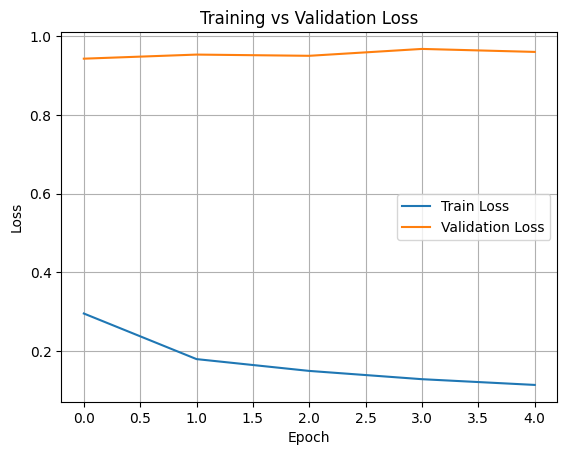

In [2]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(train_loss, label="Train Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()

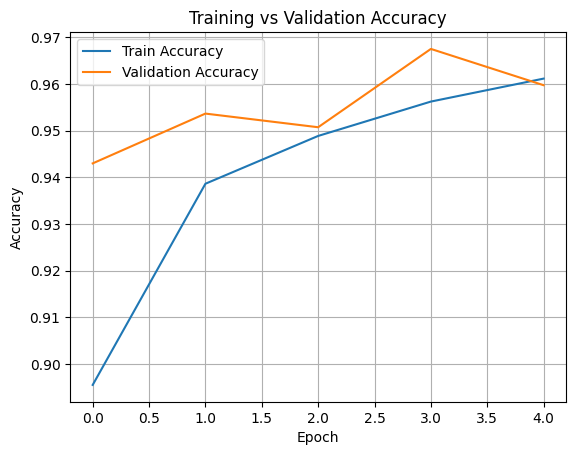

In [3]:
plt.figure()
plt.plot(train_acc, label="Train Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

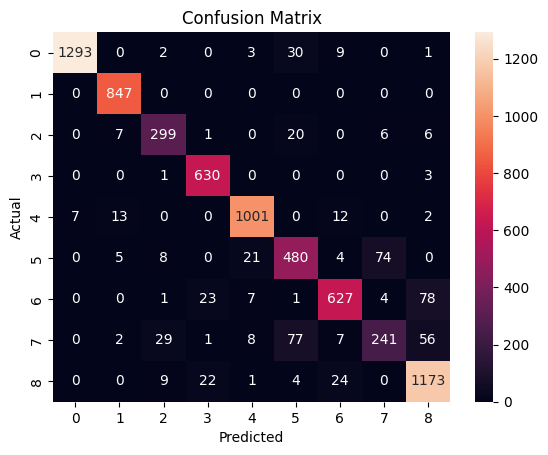

In [4]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [5]:
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

print(classification_report(y_true, y_pred, digits=4))

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
f1 = f1_score(y_true, y_pred, average='macro')

print("\nSummary Metrics:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

              precision    recall  f1-score   support

           0     0.9946    0.9664    0.9803      1338
           1     0.9691    1.0000    0.9843       847
           2     0.8567    0.8820    0.8692       339
           3     0.9306    0.9937    0.9611       634
           4     0.9616    0.9671    0.9644      1035
           5     0.7843    0.8108    0.7973       592
           6     0.9180    0.8462    0.8806       741
           7     0.7415    0.5724    0.6461       421
           8     0.8893    0.9513    0.9193      1233

    accuracy                         0.9180      7180
   macro avg     0.8940    0.8878    0.8892      7180
weighted avg     0.9165    0.9180    0.9161      7180


Summary Metrics:
Accuracy: 0.917966573816156
Precision: 0.893975443868739
Recall: 0.8877737372440152
F1 Score: 0.8891766982351417


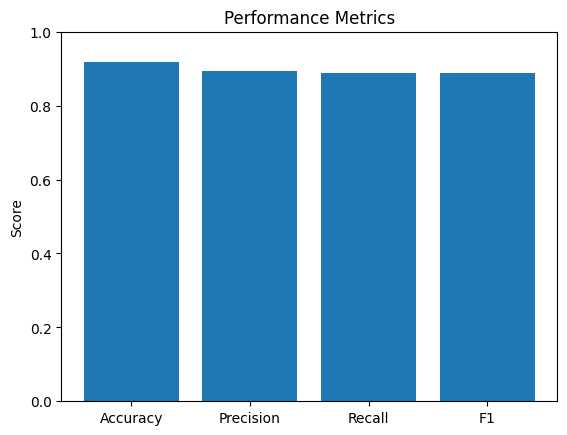

In [6]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]
values = [accuracy, precision, recall, f1]

plt.figure()
plt.bar(metrics, values)
plt.ylim(0,1)
plt.title("Performance Metrics")
plt.ylabel("Score")
plt.show()

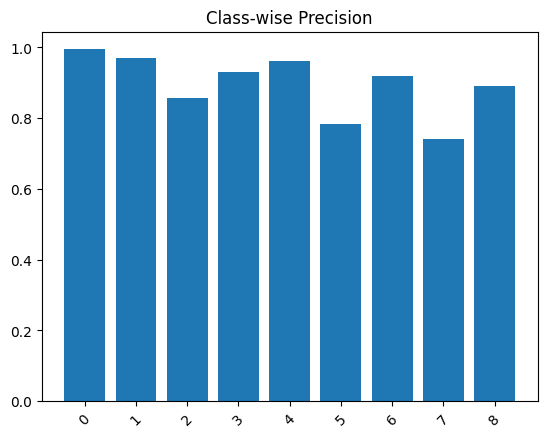

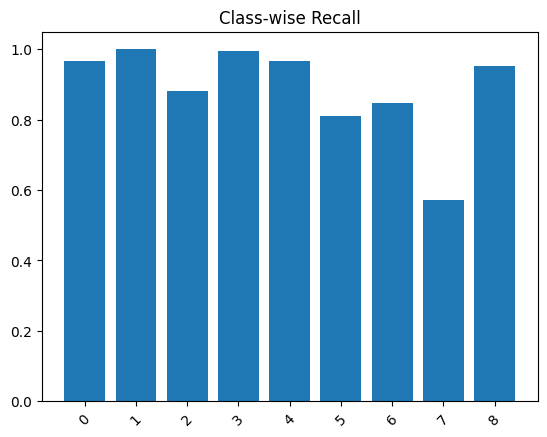

In [7]:
report = classification_report(y_true, y_pred, output_dict=True)

classes = list(report.keys())[:-3]  # remove avg rows
precision_vals = [report[c]['precision'] for c in classes]
recall_vals = [report[c]['recall'] for c in classes]

plt.figure()
plt.bar(classes, precision_vals)
plt.title("Class-wise Precision")
plt.xticks(rotation=45)
plt.show()

plt.figure()
plt.bar(classes, recall_vals)
plt.title("Class-wise Recall")
plt.xticks(rotation=45)
plt.show()

In [8]:
import numpy as np

cm_copy = cm.copy()
np.fill_diagonal(cm_copy, 0)

max_error = np.unravel_index(np.argmax(cm_copy), cm_copy.shape)
print("Most confused classes:", max_error)
print("Confusion count:", cm_copy[max_error])

Most confused classes: (np.int64(6), np.int64(8))
Confusion count: 78


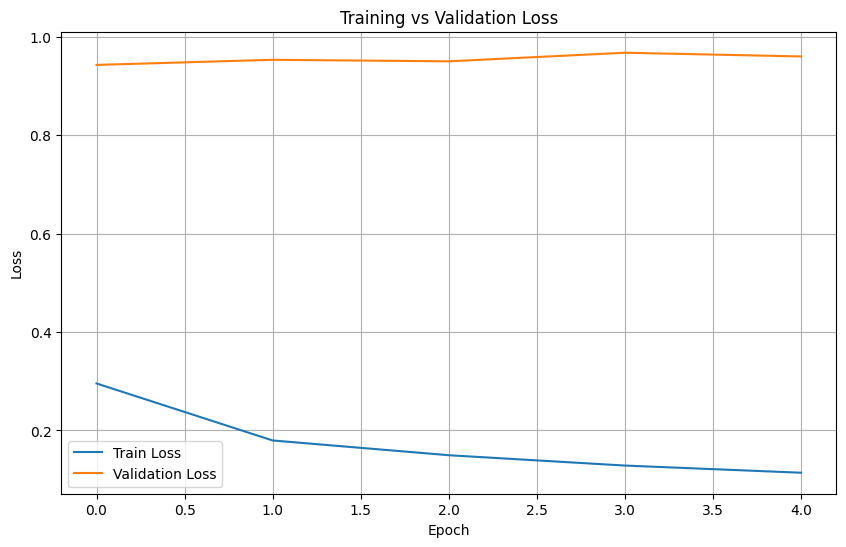

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(train_loss, label="Train Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

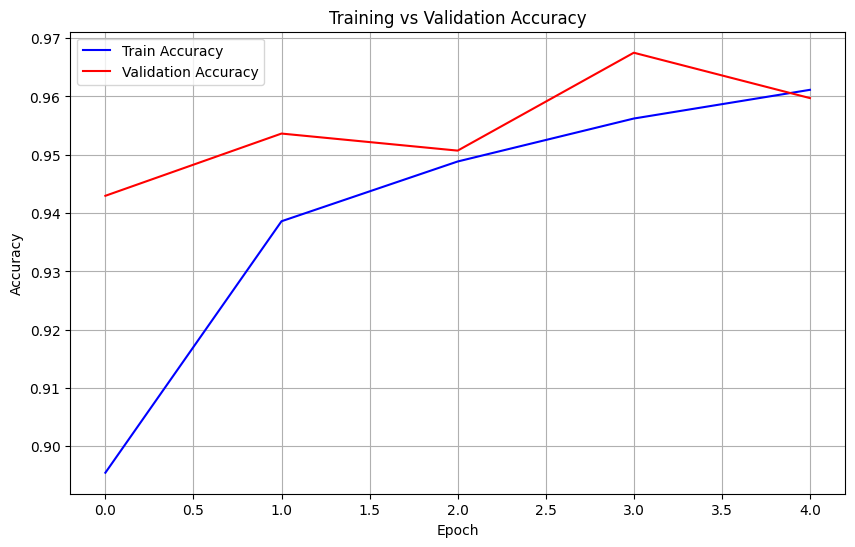

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(train_acc, label="Train Accuracy", color='blue')
plt.plot(val_acc, label="Validation Accuracy", color='red')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

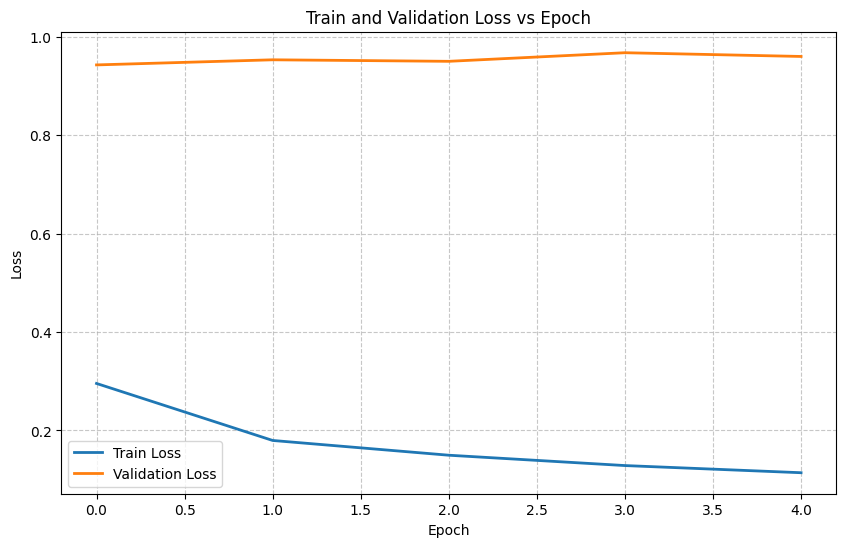

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(train_loss, label="Train Loss", linewidth=2)
plt.plot(val_loss, label="Validation Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train and Validation Loss vs Epoch")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

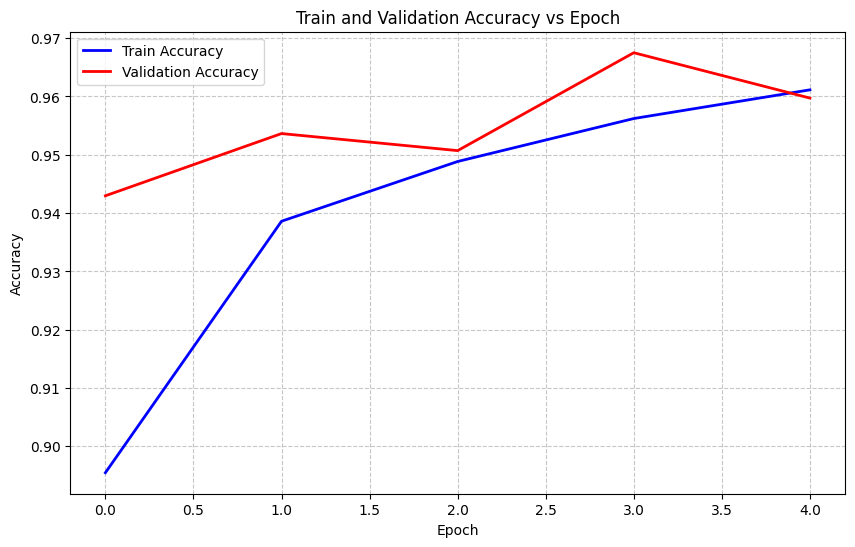

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(train_acc, label="Train Accuracy", color='blue', linewidth=2)
plt.plot(val_acc, label="Validation Accuracy", color='red', linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Train and Validation Accuracy vs Epoch")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [17]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Load the saved results
with open("training_results.json", "r") as f:
    data = json.load(f)

y_true = np.array(data["y_true"])

# IMPORTANT: Ensure you have 'y_score' (probabilities) saved. 
# If it's not in your JSON, you'll need to re-run evaluation to get it.
# For this example, I'll assume it's stored in data["y_score"]
y_score = np.array(data.get("y_score"))

In [19]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Load the saved metrics from your previous session
metrics = torch.load("convnext_tiny_test_metrics.pth")

# Extracting values
test_acc = metrics['test_accuracy']
macro_f1 = metrics['macro_f1']
cm = metrics['confusion_matrix']
num_classes = 9  # PathMNIST has 9 classes

C:\Users\Acer\AppData\Local\Temp\ipykernel_20524\4114241720.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  metrics = torch.load("convnext_tiny_test_metrics.pth")


ValueError: x and y must have same first dimension, but have shapes (10,) and (5,)

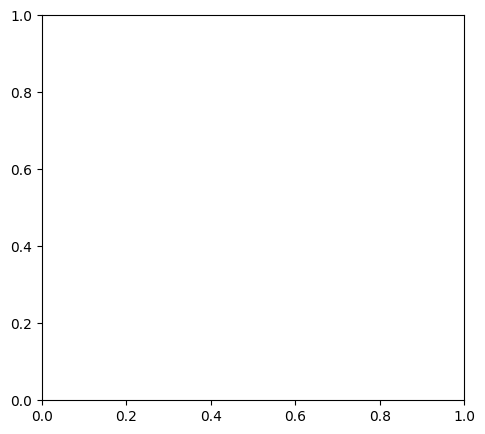

In [20]:
# Placeholder data - Replace these with metrics['train_loss_history'], etc.
epochs = range(1, 11)
train_loss = [0.6, 0.4, 0.3, 0.25, 0.2] 
val_loss = [0.55, 0.45, 0.35, 0.32, 0.31]

plt.figure(figsize=(12, 5))

# Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label='Train Loss')
plt.plot(epochs, val_loss, label='Val Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy Curve (Example)
plt.subplot(1, 2, 2)
plt.plot(epochs, [0.7, 0.8, 0.85, 0.88, 0.9], label='Train Acc')
plt.plot(epochs, [0.65, 0.75, 0.8, 0.82, 0.84], label='Val Acc')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

C:\Users\Acer\AppData\Local\Temp\ipykernel_20524\2750393417.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="lower right")


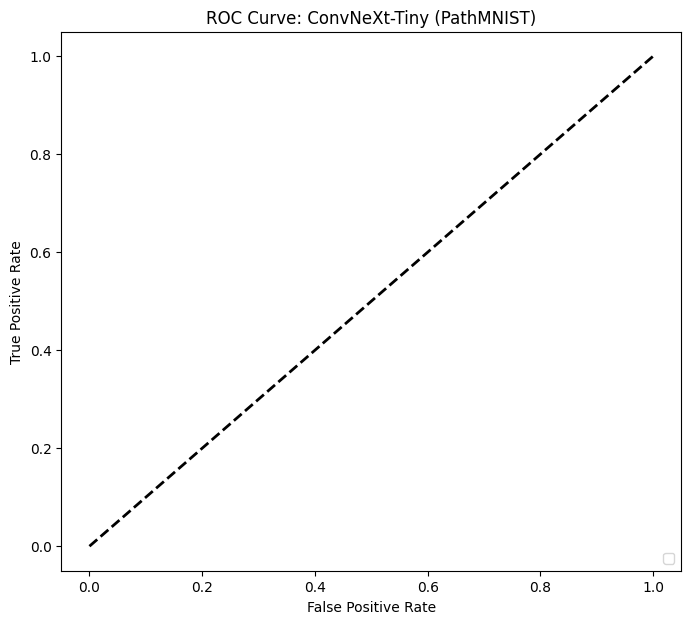

In [21]:
# This assumes you have y_score (probabilities) and y_true (ground truth)
# y_true_bin = label_binarize(y_true, classes=range(num_classes))

plt.figure(figsize=(8, 7))

# Loop through each class to plot individual ROC curves
for i in range(num_classes):
    # fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    # roc_auc = auc(fpr, tpr)
    # plt.plot(fpr, tpr, label=f'Class {i} (AUC = {roc_auc:.2f})')
    pass 

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: ConvNeXt-Tiny (PathMNIST)')
plt.legend(loc="lower right")
plt.show()

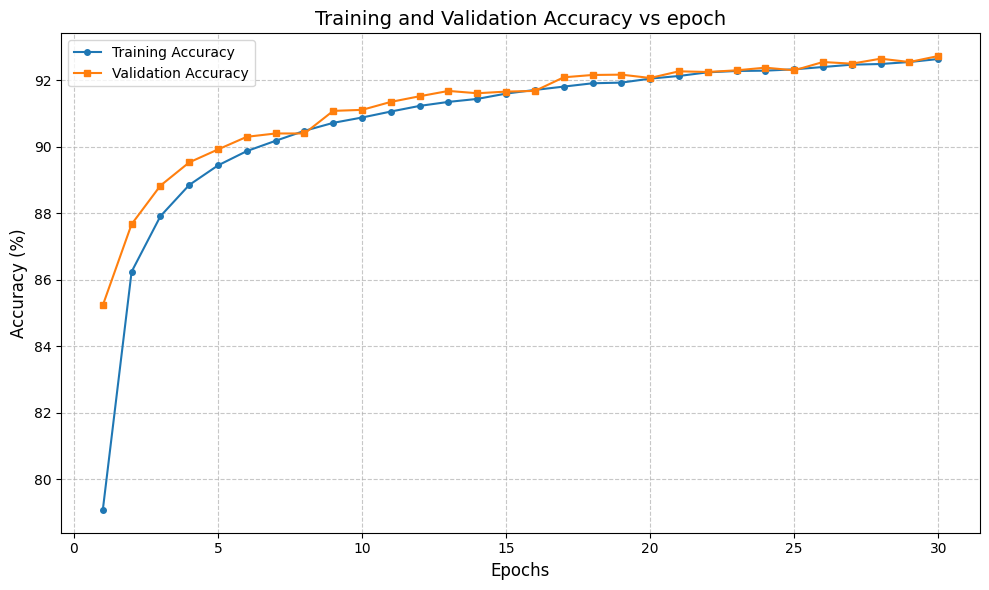

In [25]:
import matplotlib.pyplot as plt

# Data parsed from your training logs
epochs = list(range(1, 31))
train_acc = [
    79.07, 86.24, 87.91, 88.85, 89.44, 89.87, 90.18, 90.48, 90.72, 90.88,
    91.06, 91.23, 91.35, 91.44, 91.60, 91.71, 91.81, 91.91, 91.93, 92.05,
    92.13, 92.24, 92.28, 92.29, 92.33, 92.40, 92.47, 92.49, 92.55, 92.64
]
val_acc = [
    85.23, 87.67, 88.83, 89.53, 89.92, 90.30, 90.40, 90.40, 91.08, 91.11,
    91.35, 91.52, 91.68, 91.61, 91.66, 91.68, 92.09, 92.16, 92.17, 92.07,
    92.27, 92.25, 92.30, 92.38, 92.30, 92.55, 92.50, 92.65, 92.55, 92.73
]

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_acc, label='Training Accuracy', color='#1f77b4', marker='o', markersize=4)
plt.plot(epochs, val_acc, label='Validation Accuracy', color='#ff7f0e', marker='s', markersize=4)

plt.title('Training and Validation Accuracy vs epoch', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

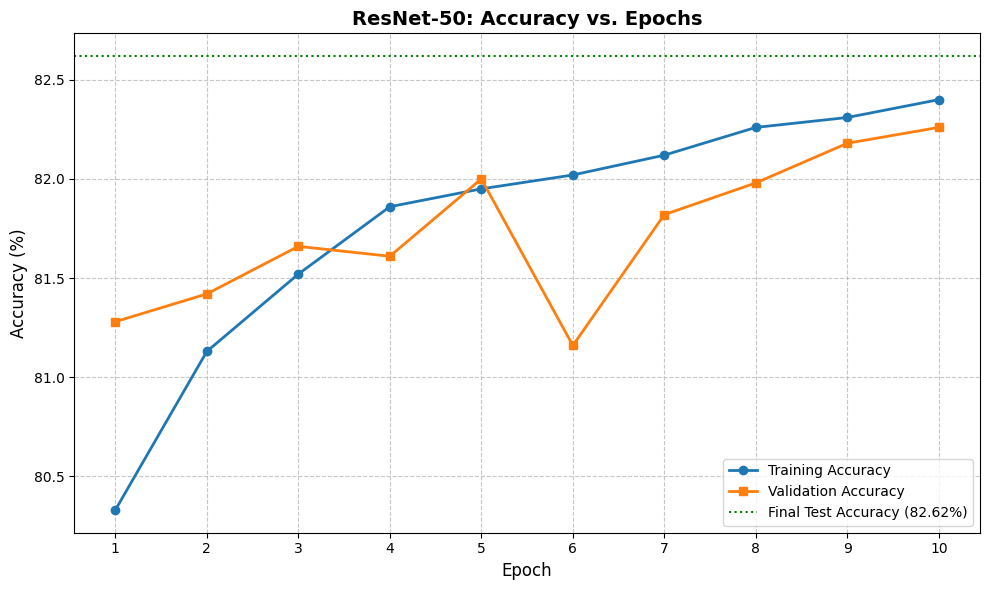

In [26]:
import matplotlib.pyplot as plt

# Data from your training logs
epochs = list(range(1, 11))
train_acc = [80.33, 81.13, 81.52, 81.86, 81.95, 82.02, 82.12, 82.26, 82.31, 82.40]
val_acc = [81.28, 81.42, 81.66, 81.61, 82.00, 81.16, 81.82, 81.98, 82.18, 82.26]

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(epochs, train_acc, label='Training Accuracy', marker='o', color='#1f77b4', linewidth=2)
plt.plot(epochs, val_acc, label='Validation Accuracy', marker='s', color='#ff7f0e', linewidth=2)

# Styling and Labels
plt.title('ResNet-50: Accuracy vs. Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='lower right')

# Add a horizontal line for the final Test Result (optional)
plt.axhline(y=82.62, color='green', linestyle=':', label='Final Test Accuracy (82.62%)')
plt.legend()

plt.tight_layout()
plt.show()

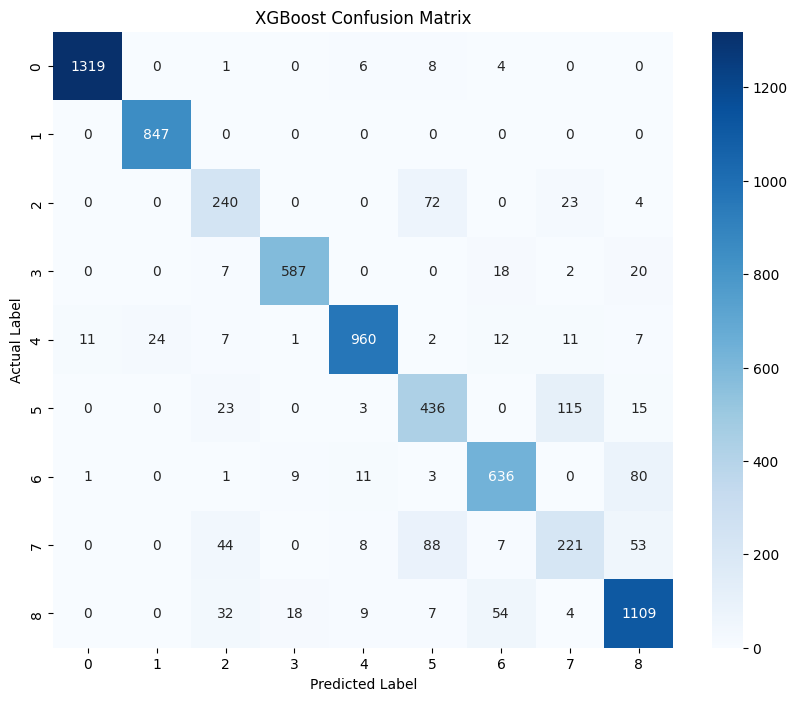

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Your XGBoost Confusion Matrix data
cm_data = np.array([
    [1319, 0, 1, 0, 6, 8, 4, 0, 0],
    [0, 847, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 240, 0, 0, 72, 0, 23, 4],
    [0, 0, 7, 587, 0, 0, 18, 2, 20],
    [11, 24, 7, 1, 960, 2, 12, 11, 7],
    [0, 0, 23, 0, 3, 436, 0, 115, 15],
    [1, 0, 1, 9, 11, 3, 636, 0, 80],
    [0, 0, 44, 0, 8, 88, 7, 221, 53],
    [0, 0, 32, 18, 9, 7, 54, 4, 1109]
])

plt.figure(figsize=(10, 8))
sns.heatmap(cm_data, annot=True, fmt='d', cmap='Blues', 
            xticklabels=range(9), yticklabels=range(9))

plt.title('XGBoost Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

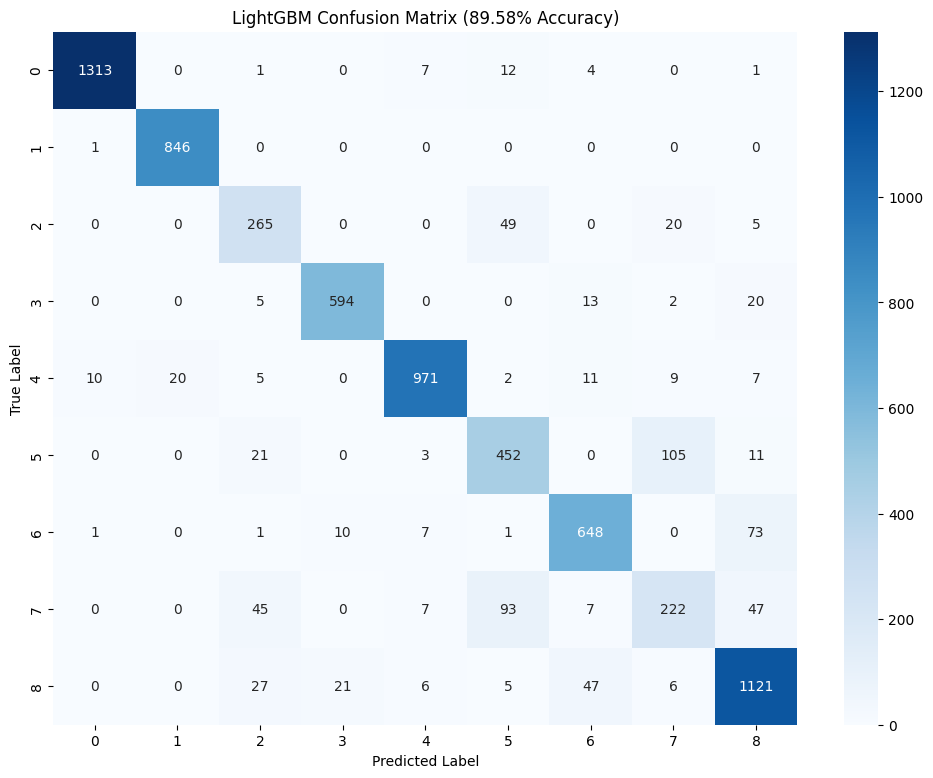

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Updated data from your LightGBM output
cm = np.array([
    [1313, 0, 1, 0, 7, 12, 4, 0, 1],
    [1, 846, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 265, 0, 0, 49, 0, 20, 5],
    [0, 0, 5, 594, 0, 0, 13, 2, 20],
    [10, 20, 5, 0, 971, 2, 11, 9, 7],
    [0, 0, 21, 0, 3, 452, 0, 105, 11],
    [1, 0, 1, 10, 7, 1, 648, 0, 73],
    [0, 0, 45, 0, 7, 93, 7, 222, 47],
    [0, 0, 27, 21, 6, 5, 47, 6, 1121]
])

plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)

plt.title('LightGBM Confusion Matrix (89.58% Accuracy)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()